# 03 – Chọn phương pháp và xây dựng mô hình (Method Selection + Model Development)

- **Học phần:** Ứng dụng AI trong công nghiệp
- **Dataset:** SECOM (1567 mẫu, 590 đặc trưng, nhãn Pass/Fail, có timestamp)
- **Mục tiêu của notebook:** So sánh và huấn luyện các mô hình phân loại Fail, so sánh class weight, chọn mô hình và chọn ngưỡng quyết định chỉ bằng dữ liệu train.
- **Bước lifecycle:** 4. Method Selection và 5. Model Development
- **Bài lab của thầy tham chiếu:** Lab 03 và Lab 06 (bài làm của em)
- **Input (đọc từ):** `data/secom/` qua `load_secom`; `artifacts/preprocessing_pipeline.joblib` (từ notebook 02). Split không đọc từ file: gọi lại `get_split` và kiểm tra 1253 / 314, Fail 83 / 21.
- **Output (lưu vào):** `artifacts/model_lr.joblib`, `model_rf.joblib`, `model_final.joblib`, `decision_config.json`; bảng `artifacts/results/cv_model_comparison.csv`, `cv_class_weight.csv`, `oof_predictions.csv`, `threshold_oof.csv`; hình `figures/fig_03_*.png`

**Notebook này không dự đoán và không tính chỉ số trên test.** Mọi so sánh, chọn mô hình và chọn ngưỡng chỉ dùng `X_train_raw`, `y_train`.

**Thiết lập mặc định** (chưa phải yêu cầu đã chốt của nhóm; có thể đổi **trước khi mở test** ở notebook 04):

| Nội dung | Mặc định | Lý do |
|---|---|---|
| Mô hình | Logistic Regression, Random Forest, cấu hình cơ sở của thầy, k = 40 cố định | Đề chỉ cần ít nhất 2 phương pháp |
| CV | Stratified 5-fold, shuffle, seed 42, chỉ trên train | Kế thừa Lab 06 |
| Chọn mô hình | AP trung bình CV cao nhất; bằng điểm thì chọn Logistic Regression | Quy tắc xác định trước, phù hợp lớp hiếm |
| Class weight (LR) | So sánh 3 mức `None`, `"balanced"`, `{0:1, 1:10}`; dùng `"balanced"` trừ khi một mức khác hơn rõ hơn độ lệch chuẩn giữa các fold | AP ít đổi theo class weight; ngưỡng mới là bước quyết định |
| Chọn ngưỡng | F1 của Fail cao nhất trên dự đoán out-of-fold (OOF) của train; F1 bằng nhau thì chọn ngưỡng cao hơn | Chưa có chi phí hay năng lực kiểm tra thật |
| Chi phí tiền tệ | Không đưa vào kết quả | SECOM không có chi phí |

**Nhãn từng mục:** *Kế thừa từ lab*, *Điều chỉnh từ lab*, *Nhóm bổ sung*.

## 0. Import và đường dẫn

*Nhãn: Kế thừa từ lab (Lab 03, cell 6); điều chỉnh: dùng `secom_utils` và `Path`.*

Khai báo thư viện, hằng số và đường dẫn dùng chung.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ttest_ind
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

from secom_utils import (
    SEED, TEST_SIZE,
    ARTIFACT_DIR, RESULTS_DIR, FIGURES_DIR,
    load_secom, get_split, save_artifact, load_artifact,
    evaluate_classifier, choose_threshold,
)
from secom_preprocessing import MissingRateSelector  # cần import được để nạp pipeline đã lưu

K_FEATURES = 40  # số đặc trưng giữ lại bằng F-test, cố định

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 50)

FIGURES_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("SEED =", SEED, "| K_FEATURES =", K_FEATURES)

SEED = 42 | K_FEATURES = 40


## 1. Nạp dữ liệu, split và pipeline tiền xử lý

*Nhãn: Điều chỉnh từ lab (Lab 03, mục 6–9: không đọc lại ma trận đã biến đổi mà dựng pipeline đầy đủ trên dữ liệu thô).*

Gọi lại `get_split`, dựng train, kiểm tra số dòng và số Fail; nạp pipeline tiền xử lý của notebook 02. Pipeline đã fit này **chỉ dùng làm khuôn** (`clone`): trong CV, mỗi fold fit lại cả chuỗi từ dữ liệu thô, nên không lấy ma trận đã biến đổi ở notebook 02 đưa vào CV (nếu làm vậy, trung vị và độ lệch chuẩn đã nhìn thấy cả các fold validation).

In [2]:
X, y, timestamp = load_secom()

train_idx, test_idx = get_split(y, test_size=TEST_SIZE, seed=SEED)
X_train_raw = X.iloc[train_idx]
y_train = y.iloc[train_idx]

# Kiểm tra split đã chốt: lệch thì báo lỗi, không âm thầm đi tiếp
assert (len(train_idx), len(test_idx)) == (1253, 314), "Số dòng train/test lệch 1253/314"
assert (int(y_train.sum()), int(y.iloc[test_idx].sum())) == (83, 21), "Số Fail train/test lệch 83/21"

print("X_train_raw:", X_train_raw.shape, "| Fail:", int(y_train.sum()), "| Pass:", int((y_train == 0).sum()))
print("Split đúng: train/test = 1253 / 314, Fail train/test = 83 / 21")
print("Tỷ lệ Fail của train:", round(y_train.mean() * 100, 2), "%")

X_train_raw: (1253, 590) | Fail: 83 | Pass: 1170
Split đúng: train/test = 1253 / 314, Fail train/test = 83 / 21
Tỷ lệ Fail của train: 6.62 %


In [3]:
preprocessing_pipeline = load_artifact("preprocessing_pipeline.joblib")
print("Các bước của pipeline tiền xử lý (notebook 02):")
for step_name, step in preprocessing_pipeline.steps:
    print("  -", step_name, ":", type(step).__name__)
print("Số cột đầu vào pipeline nhận:", preprocessing_pipeline.named_steps["missing_rate"].n_features_in_)

Các bước của pipeline tiền xử lý (notebook 02):
  - missing_rate : MissingRateSelector
  - imputer : SimpleImputer
  - constant : VarianceThreshold
  - scaler : StandardScaler
Số cột đầu vào pipeline nhận: 590


### Nhận xét

- **Phát hiện:** split dựng lại bằng `get_split` cho đúng train 1.253 (Fail 83) và test 314 (Fail 21); pipeline của notebook 02 gồm 4 bước và nhận 590 cột thô.
- **Ảnh hưởng:** từ đây notebook chỉ giữ `X_train_raw` và `y_train`; không có biến nào chứa dự đoán hay điểm số trên test.
- **Kết luận:** mô hình được dựng như một pipeline đầy đủ nhận dữ liệu thô, để CV và model lưu ra đều nhận thẳng 590 cột.

## 2. Lý do chọn phương pháp

*Nhãn: Nhóm bổ sung (Lab 03 chỉ giới thiệu ngắn); điều chỉnh: hai mô hình cấu hình cơ sở của thầy, không tuning.*

Đề yêu cầu so sánh ít nhất hai phương pháp. Chọn Logistic Regression và Random Forest. Mô hình không được chọn theo Accuracy vì luôn dự đoán Pass đã đạt khoảng 93,4%.

In [4]:
method_rows = [
    {
        "Mô hình": "Logistic Regression",
        "Vai trò": "Mô hình tuyến tính, dễ đọc hệ số",
        "Nhạy thang đo": "Có (đã chuẩn hoá ở pipeline)",
        "Quan hệ phi tuyến": "Không",
        "Dễ giải thích": "Dễ: hệ số có dấu theo từng đặc trưng",
        "Chi phí": "Thấp",
        "Hạn chế": "Chỉ học ranh giới tuyến tính; cột tương quan cao làm hệ số kém ổn định",
    },
    {
        "Mô hình": "Random Forest",
        "Vai trò": "Mô hình phi tuyến dạng cây",
        "Nhạy thang đo": "Không",
        "Quan hệ phi tuyến": "Có",
        "Dễ giải thích": "Vừa: có importance nhưng không có dấu",
        "Chi phí": "Cao hơn (200 cây)",
        "Hạn chế": "Với 83 Fail dễ học thiên về lớp Pass; importance bị cột tương quan chia nhỏ",
    },
]
method_table = pd.DataFrame(method_rows)
with pd.option_context("display.max_colwidth", None):
    display(method_table)

,Mô hình,Vai trò,Nhạy thang đo,Quan hệ phi tuyến,Dễ giải thích,Chi phí,Hạn chế
0,Logistic Regression,"Mô hình tuyến tính, dễ đọc hệ số",Có (đã chuẩn hoá ở pipeline),Không,Dễ: hệ số có dấu theo từng đặc trưng,Thấp,Chỉ học ranh giới tuyến tính; cột tương quan cao làm hệ số kém ổn định
1,Random Forest,Mô hình phi tuyến dạng cây,Không,Có,Vừa: có importance nhưng không có dấu,Cao hơn (200 cây),Với 83 Fail dễ học thiên về lớp Pass; importance bị cột tương quan chia nhỏ


In [5]:
# Một bộ fold dùng chung cho mọi so sánh trong notebook
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

for fold_number, (fit_positions, valid_positions) in enumerate(cv.split(X_train_raw, y_train), start=1):
    n_fail_valid = int(y_train.iloc[valid_positions].sum())
    print(f"Fold {fold_number}: fit {len(fit_positions)} mẫu, validation {len(valid_positions)} mẫu (Fail: {n_fail_valid})")

Fold 1: fit 1002 mẫu, validation 251 mẫu (Fail: 17)
Fold 2: fit 1002 mẫu, validation 251 mẫu (Fail: 17)
Fold 3: fit 1002 mẫu, validation 251 mẫu (Fail: 17)
Fold 4: fit 1003 mẫu, validation 250 mẫu (Fail: 16)
Fold 5: fit 1003 mẫu, validation 250 mẫu (Fail: 16)


### Nhận xét

- **Phát hiện:** hai mô hình khác nhau ở độ nhạy thang đo, khả năng học quan hệ phi tuyến và độ dễ giải thích. Mỗi fold validation chỉ có khoảng 16–17 Fail.
- **Ảnh hưởng:** không thể biết trước mô hình phi tuyến có tốt hơn mô hình tuyến tính trên SECOM; với ít Fail như vậy, chênh lệch giữa hai mô hình có thể nhỏ hơn độ dao động giữa các fold.
- **Kết luận:** so sánh trên cùng một bộ fold, báo mean ± std, không chọn theo Accuracy, và không khẳng định mô hình nào hơn khi chênh lệch nhỏ hơn độ lệch chuẩn.

## 3. Chọn đặc trưng bằng F-test và T-test

*Nhãn: Kế thừa từ lab (Lab 03, cell 20, 22, 24); điều chỉnh: ánh xạ về **chỉ số cột gốc 0–589** (Lab 03 chỉ in chỉ số sau tiền xử lý).*

Trong CV, `SelectKBest(f_classif, k=40)` là một bước **bên trong** pipeline, nên được fit lại trong từng fold. Ô dưới fit tiền xử lý và F-test trên **toàn bộ train** chỉ để xem 40 cột được chọn và ánh xạ về cột gốc; kết quả này không đưa vào CV. Welch T-test cũng chỉ trên train, để minh hoạ, không dùng để chọn.

In [6]:
# Chỉ để minh hoạ: fit tiền xử lý + F-test trên toàn bộ train (không dùng test)
illustration_preprocess = clone(preprocessing_pipeline)
X_train_processed = illustration_preprocess.fit_transform(X_train_raw)

# Kiểm tra: clone rồi fit lại trên train cho đúng kết quả của pipeline đã lưu ở notebook 02
assert np.allclose(X_train_processed, preprocessing_pipeline.transform(X_train_raw)), "Pipeline 02 và bản fit lại khác nhau"

illustration_selector = SelectKBest(score_func=f_classif, k=K_FEATURES)
illustration_selector.fit(X_train_processed, y_train)

print("Số cột sau tiền xử lý:", X_train_processed.shape[1])
print("Số cột được chọn:", illustration_selector.get_support().sum())

Số cột sau tiền xử lý:

 466
Số cột được chọn: 40


In [7]:
# Ánh xạ về cột gốc 0-589: lần theo mask của từng bước (missing_rate -> constant -> SelectKBest)
index_after_missing = illustration_preprocess.named_steps["missing_rate"].get_support(indices=True)
position_after_constant = illustration_preprocess.named_steps["constant"].get_support(indices=True)
position_after_select = illustration_selector.get_support(indices=True)

index_after_constant = index_after_missing[position_after_constant]
selected_original_columns = index_after_constant[position_after_select]

# Độ dài từng bước phải khớp nhau
print("Sau missing_rate:", len(index_after_missing), "| sau constant:", len(index_after_constant), "| sau SelectKBest:", len(selected_original_columns))
assert len(index_after_constant) == X_train_processed.shape[1] == len(illustration_selector.scores_)
assert len(selected_original_columns) == K_FEATURES
assert selected_original_columns.min() >= 0 and selected_original_columns.max() <= 589

f_score_table = pd.DataFrame({
    "Cột gốc": index_after_constant,
    "F_score": illustration_selector.scores_,
}).sort_values("F_score", ascending=False).reset_index(drop=True)

# Top 40 theo F-score phải trùng tập cột mà SelectKBest chọn
assert set(f_score_table["Cột gốc"].head(K_FEATURES)) == set(selected_original_columns)

display(f_score_table.head(15))
print("40 cột gốc được chọn (sắp tăng dần):", [int(c) for c in selected_original_columns])

Sau missing_rate: 582 | sau constant: 466 | sau SelectKBest: 40


,Cột gốc,F_score
0,103,38.345328
1,510,26.408693
2,59,20.145968
3,348,15.719980
4,129,14.664044
5,431,14.090072
6,64,13.675521
7,21,12.463758
8,125,11.306550
9,430,10.875200


40 cột gốc được chọn (sắp tăng dần): [14, 21, 28, 59, 64, 65, 70, 95, 100, 103, 114, 121, 122, 124, 125, 127, 129, 130, 160, 163, 180, 210, 213, 247, 249, 295, 298, 316, 348, 351, 365, 387, 430, 431, 434, 435, 436, 452, 455, 510]


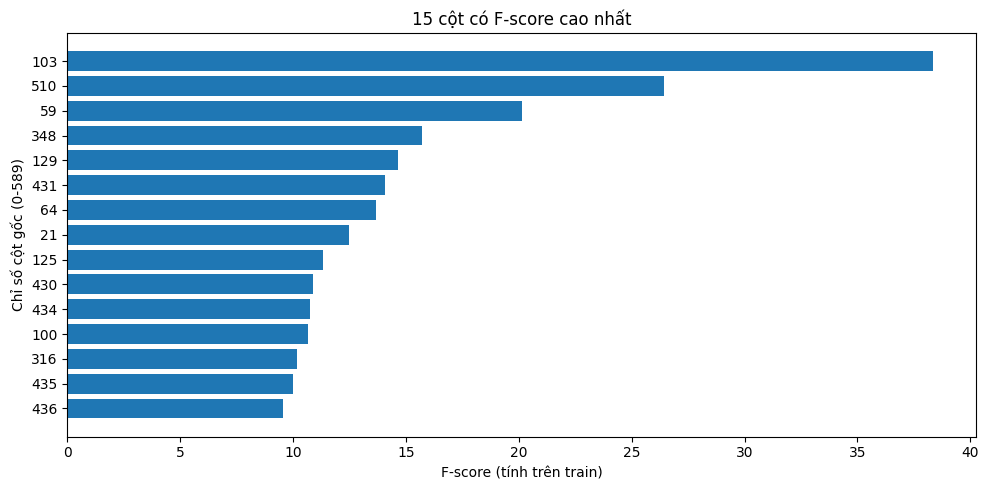

In [8]:
top_f = f_score_table.head(15).sort_values("F_score")

plt.figure(figsize=(10, 5))
plt.barh(top_f["Cột gốc"].astype(str), top_f["F_score"], color="tab:blue")
plt.xlabel("F-score (tính trên train)")
plt.ylabel("Chỉ số cột gốc (0-589)")
plt.title("15 cột có F-score cao nhất")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_03_ftest_top15.png", dpi=150)
plt.show()

In [9]:
# Welch T-test trên train: so Pass và Fail theo từng cột (minh hoạ phụ)
is_fail = (y_train.to_numpy() == 1)
t_statistics, _ = ttest_ind(X_train_processed[~is_fail], X_train_processed[is_fail], equal_var=False)
assert not np.isnan(t_statistics).any(), "T-test có giá trị NaN"

t_top_positions = np.argsort(-np.abs(t_statistics))[:K_FEATURES]
overlap = len(set(position_after_select) & set(t_top_positions))

print("Số cột trùng giữa top 40 của F-test và top 40 của T-test:", overlap, "/", K_FEATURES)

Số cột trùng giữa top 40 của F-test và top 40 của T-test: 22 / 40


C:\Users\Admin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\scipy\stats\_axis_nan_policy.py:635: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, axis=axis, **kwds)


### Nhận xét

- **Phát hiện:** F-test fit trên toàn bộ train chọn 40/466 cột; đã ánh xạ về chỉ số cột gốc 0–589 (độ dài các bước khớp nhau, top 40 theo F-score trùng tập `SelectKBest` chọn). Cột có F-score cao nhất là 103 (F = 38,35). Top 40 của Welch T-test trùng 22/40 cột với F-test.
- **Ảnh hưởng:** hai tiêu chí cho tập cột khác nhau một phần, nên chọn đặc trưng phụ thuộc tiêu chí. Số cột chọn (40) cố định, không tuning.
- **Cảnh báo khi chạy T-test:** scipy báo `RuntimeWarning` về mất độ chính xác khi dữ liệu gần như giống nhau, nghĩa là một số cột gần như không đổi trong một nhóm nên t-statistic của các cột đó kém tin cậy. Vì T-test chỉ là minh hoạ phụ, không dùng để chọn, nên giữ nguyên cảnh báo và không xử lý thêm.
- **Kết luận:** dùng F-test (k = 40) làm bước chọn đặc trưng trong pipeline đầy đủ. Danh sách 40 cột gốc này không đưa vào CV; ở mục 10 sẽ kiểm tra lại model cuối chọn đúng tập này và lưu vào `decision_config.json`. Điểm F-test chỉ đo liên hệ đơn biến với nhãn, không phải quan hệ nhân quả.

### Pipeline đầy đủ và hàm chạy CV

*Nhãn: Điều chỉnh từ lab (Lab 03 fit từng bước riêng; ở đây gói cả chuỗi vào một `Pipeline` để CV fit lại trong từng fold).*

```text
MissingRateSelector → Median imputer → VarianceThreshold → Scaler → SelectKBest → Classifier
```

Hai hàm dưới được gọi nhiều lần (LR, RF, các mức class weight) nên tách thành hàm. Ngưỡng ở bước so sánh này là 0,5 (mặc định của `predict`); ngưỡng riêng chọn ở mục 8.

In [10]:
def make_full_pipeline(classifier):
    # Tiền xử lý (bản clone chưa fit của notebook 02) -> chọn đặc trưng -> mô hình
    return Pipeline([
        ("preprocess", clone(preprocessing_pipeline)),
        ("select", SelectKBest(score_func=f_classif, k=K_FEATURES)),
        ("model", classifier),
    ])


scoring = {
    "average_precision": "average_precision",
    "recall_fail": make_scorer(recall_score, zero_division=0),
    "precision_fail": make_scorer(precision_score, zero_division=0),
    "f1_fail": make_scorer(f1_score, zero_division=0),
    "balanced_accuracy": "balanced_accuracy",
}


def run_cv(name, estimator):
    # CV trên train thô: mỗi fold fit lại cả pipeline. BER mỗi fold = 1 - Balanced Accuracy
    scores = cross_validate(estimator, X_train_raw, y_train, cv=cv, scoring=scoring)
    per_fold = {
        "AP": scores["test_average_precision"],
        "Recall_Fail": scores["test_recall_fail"],
        "Precision_Fail": scores["test_precision_fail"],
        "F1_Fail": scores["test_f1_fail"],
        "Balanced_Accuracy": scores["test_balanced_accuracy"],
        "BER": 1 - scores["test_balanced_accuracy"],
    }
    row = {"Mô hình": name}
    for metric_name, values in per_fold.items():
        row[metric_name + "_mean"] = values.mean()
        row[metric_name + "_std"] = values.std()  # độ lệch chuẩn tổng thể (ddof = 0) giữa 5 fold
    return row

## 4. Logistic Regression

*Nhãn: Kế thừa từ lab (Lab 03, cell 33): cấu hình `max_iter=2000, class_weight="balanced"`; điều chỉnh: đặt trong pipeline đầy đủ, đánh giá bằng CV trên train.*

In [11]:
lr_base = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
lr_row = run_cv("Logistic Regression (balanced)", make_full_pipeline(lr_base))

display(pd.DataFrame([lr_row]).round(4))
print("Tỷ lệ Fail của train (mốc AP ngẫu nhiên):", round(y_train.mean(), 4))

,Mô hình,AP_mean,AP_std,Recall_Fail_mean,Recall_Fail_std,Precision_Fail_mean,Precision_Fail_std,F1_Fail_mean,F1_Fail_std,Balanced_Accuracy_mean,Balanced_Accuracy_std,BER_mean,BER_std
0,Logistic Regression (balanced),0.1631,0.029,0.4581,0.0608,0.1246,0.0213,0.1956,0.0311,0.6137,0.0359,0.3863,0.0359


Tỷ lệ Fail của train (mốc AP ngẫu nhiên): 0.0662


### Nhận xét

- **Phát hiện:** Logistic Regression (`balanced`, ngưỡng 0,5) có AP = 0,163 ± 0,029, Recall của Fail = 0,458 ± 0,061, Precision của Fail = 0,125 ± 0,021, BER = 0,386 ± 0,036 (mean ± std giữa 5 fold).
- **Ảnh hưởng:** so với mốc tỷ lệ Fail của train (6,6%), AP cao hơn; Precision thấp nghĩa là phần lớn cảnh báo ở ngưỡng 0,5 là Pass bị báo nhầm.
- **Kết luận:** mô hình tuyến tính có AP cao hơn mốc tỷ lệ Fail của train nhưng ở mức khiêm tốn; ngưỡng 0,5 chưa chắc phù hợp, sẽ chọn lại ở mục 8.

## 5. Random Forest

*Nhãn: Kế thừa từ lab (Lab 03, cell 35): cấu hình `n_estimators=200, class_weight="balanced"`; điều chỉnh: đặt trong pipeline đầy đủ, đánh giá bằng CV trên train.*

In [12]:
rf_base = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED, n_jobs=-1)
rf_row = run_cv("Random Forest (balanced)", make_full_pipeline(rf_base))

display(pd.DataFrame([rf_row]).round(4))

,Mô hình,AP_mean,AP_std,Recall_Fail_mean,Recall_Fail_std,Precision_Fail_mean,Precision_Fail_std,F1_Fail_mean,F1_Fail_std,Balanced_Accuracy_mean,Balanced_Accuracy_std,BER_mean,BER_std
0,Random Forest (balanced),0.2038,0.0701,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.0,0.5,0.0


### Nhận xét

- **Phát hiện:** Random Forest (`balanced`, ngưỡng 0,5) có AP = 0,204 ± 0,070, Recall của Fail = 0 ± 0, Precision của Fail = 0 ± 0, BER = 0,5 ± 0.
- **Ảnh hưởng:** Recall và Precision đều bằng 0 nghĩa là ở ngưỡng 0,5 không quan sát nào được gắn cờ (không điểm nào đạt 0,5), nhưng AP vẫn cao hơn Logistic Regression. Xếp hạng (AP) và nhãn ở ngưỡng 0,5 là hai việc khác nhau, nên chưa thể kết luận mô hình xấu chỉ từ Recall ở một ngưỡng.
- **Kết luận:** so sánh Logistic Regression và Random Forest theo AP ở mục 7, độc lập với ngưỡng.

## 6. So sánh class weight

*Nhãn: Kế thừa từ lab (bài làm Lab 06, cell 16, 18); điều chỉnh: chạy bằng CV trên train thay vì trên test, chỉ 3 mức.*

Logistic Regression với k = 40, `C = 1`, cùng bộ fold. Class weight chỉ đổi mức phạt khi huấn luyện, **không** thêm hay bớt mẫu. Quy tắc chọn đã đặt trước: dùng `"balanced"` như Lab 03, trừ khi một mức khác có AP trung bình cao hơn `"balanced"` nhiều hơn độ lệch chuẩn AP giữa các fold của `"balanced"`.

In [13]:
class_weight_options = {
    "None": None,
    "balanced": "balanced",
    "{0:1, 1:10}": {0: 1, 1: 10},
}

class_weight_rows = []
for option_name, option_value in class_weight_options.items():
    lr_option = LogisticRegression(max_iter=2000, C=1.0, class_weight=option_value, random_state=SEED)
    class_weight_rows.append(run_cv("LR class_weight=" + option_name, make_full_pipeline(lr_option)))

class_weight_table = pd.DataFrame(class_weight_rows)
class_weight_table.insert(0, "class_weight", list(class_weight_options.keys()))
display(class_weight_table.round(4))

,class_weight,Mô hình,AP_mean,AP_std,Recall_Fail_mean,Recall_Fail_std,Precision_Fail_mean,Precision_Fail_std,F1_Fail_mean,F1_Fail_std,Balanced_Accuracy_mean,Balanced_Accuracy_std,BER_mean,BER_std
0,None,LR class_weight=None,0.1523,0.0357,0.0478,0.0442,0.1317,0.1265,0.0696,0.0651,0.5158,0.0201,0.4842,0.0201
1,balanced,LR class_weight=balanced,0.1631,0.0290,0.4581,0.0608,0.1246,0.0213,0.1956,0.0311,0.6137,0.0359,0.3863,0.0359
2,"{0:1, 1:10}","LR class_weight={0:1, 1:10}",0.1651,0.0317,0.4096,0.0422,0.1457,0.0203,0.2143,0.0257,0.6185,0.0230,0.3815,0.0230


In [14]:
# Áp dụng quy tắc đã đặt trước
balanced_position = list(class_weight_options.keys()).index("balanced")
balanced_ap = class_weight_table.loc[balanced_position, "AP_mean"]
balanced_ap_std = class_weight_table.loc[balanced_position, "AP_std"]

best_position = int(class_weight_table["AP_mean"].idxmax())
best_ap = class_weight_table.loc[best_position, "AP_mean"]
gap = best_ap - balanced_ap

print("AP trung bình của 'balanced':", round(balanced_ap, 4), "| std giữa các fold:", round(balanced_ap_std, 4))
print("Mức có AP cao nhất:", class_weight_table.loc[best_position, "class_weight"], "| AP:", round(best_ap, 4))
print("Chênh so với 'balanced':", round(gap, 4))

if gap > balanced_ap_std:
    chosen_class_weight_name = class_weight_table.loc[best_position, "class_weight"]
else:
    chosen_class_weight_name = "balanced"
chosen_class_weight = class_weight_options[chosen_class_weight_name]
print("Class weight được chọn cho Logistic Regression:", chosen_class_weight_name)

AP trung bình của 'balanced': 0.1631 | std giữa các fold: 0.029
Mức có AP cao nhất: {0:1, 1:10} | AP: 0.1651
Chênh so với 'balanced': 0.002
Class weight được chọn cho Logistic Regression: balanced


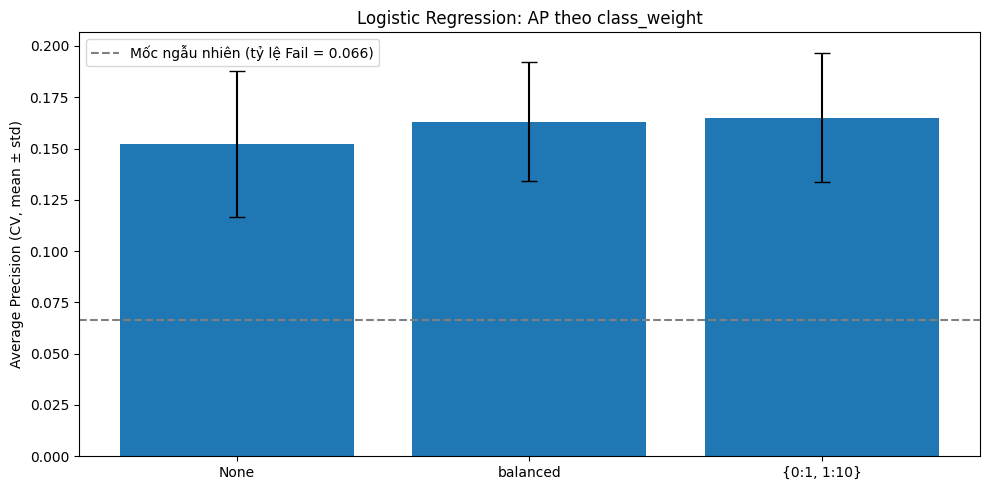

In [15]:
plt.figure(figsize=(10, 5))
plt.bar(class_weight_table["class_weight"], class_weight_table["AP_mean"],
        yerr=class_weight_table["AP_std"], capsize=6, color="tab:blue")
plt.axhline(y_train.mean(), color="gray", linestyle="--", label=f"Mốc ngẫu nhiên (tỷ lệ Fail = {y_train.mean():.3f})")
plt.ylabel("Average Precision (CV, mean ± std)")
plt.title("Logistic Regression: AP theo class_weight")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_03_class_weight_ap.png", dpi=150)
plt.show()

### Nhận xét

- **Phát hiện:** AP trung bình của ba mức lần lượt là 0,152 (`None`), 0,163 (`balanced`) và 0,165 (`{0:1, 1:10}`); độ lệch chuẩn AP giữa các fold của `balanced` là 0,029.
- **Ảnh hưởng:** class weight đổi cách mô hình trọng số hoá lỗi nên đổi nhãn dự đoán ở ngưỡng 0,5 (xem Recall và Precision trong bảng), nhưng AP đo khả năng xếp hạng nên ít bị ảnh hưởng.
- **Kết luận:** theo quy tắc đã đặt trước, class weight được chọn là **balanced**: mức `{0:1, 1:10}` chỉ hơn khoảng 0,002 AP, nhỏ hơn nhiều so với độ lệch chuẩn 0,029. Khác biệt đáng kể nằm ở nhãn ở ngưỡng 0,5: `None` gần như không gắn cờ Fail (Recall 0,048), còn `balanced` và `{0:1, 1:10}` có Recall 0,458 và 0,410.

## 7. Chọn mô hình

*Nhãn: Nhóm bổ sung (quy tắc chọn xác định trước); bỏ tuning siêu tham số, dùng cấu hình cơ sở.*

Chọn giữa Logistic Regression (với class weight vừa chọn) và Random Forest theo **AP trung bình CV cao nhất**; bằng điểm thì chọn Logistic Regression. Không chọn theo Accuracy hay theo kết quả test.

In [16]:
# Dòng của Logistic Regression lấy từ bảng class weight với mức đã chọn (cùng bộ fold)
lr_final_row = dict(class_weight_table.loc[class_weight_table["class_weight"] == chosen_class_weight_name].iloc[0])
lr_final_row["Mô hình"] = "Logistic Regression (class_weight=" + chosen_class_weight_name + ")"

# Nếu mức được chọn là balanced thì phải trùng kết quả mục 4 (cùng cấu hình, cùng fold)
if chosen_class_weight_name == "balanced":
    assert np.isclose(lr_final_row["AP_mean"], lr_row["AP_mean"]), "Kết quả LR ở mục 4 và mục 6 không trùng"

lr_ap, rf_ap = lr_final_row["AP_mean"], rf_row["AP_mean"]
ap_gap = abs(lr_ap - rf_ap)
larger_std = max(lr_final_row["AP_std"], rf_row["AP_std"])

if rf_ap > lr_ap:
    final_model_name = "random_forest"
else:
    final_model_name = "logistic_regression"   # AP cao hơn hoặc bằng thì chọn LR

print("AP trung bình LR:", round(lr_ap, 4), "±", round(lr_final_row["AP_std"], 4))
print("AP trung bình RF:", round(rf_ap, 4), "±", round(rf_row["AP_std"], 4))
print("Chênh lệch AP:", round(ap_gap, 4), "| độ lệch chuẩn lớn hơn giữa 2 mô hình:", round(larger_std, 4))
print("Mô hình được chọn:", final_model_name)
if ap_gap < larger_std:
    print("Lưu ý: chênh lệch nhỏ hơn độ lệch chuẩn giữa các fold, không khẳng định mô hình này hơn chắc chắn.")

AP trung bình LR: 0.1631 ± 0.029
AP trung bình RF: 0.2038 ± 0.0701
Chênh lệch AP: 0.0407 | độ lệch chuẩn lớn hơn giữa 2 mô hình: 0.0701
Mô hình được chọn: random_forest
Lưu ý: chênh lệch nhỏ hơn độ lệch chuẩn giữa các fold, không khẳng định mô hình này hơn chắc chắn.


### Nhận xét

- **Phát hiện:** AP trung bình CV của Logistic Regression là 0,163 ± 0,029 và của Random Forest là 0,204 ± 0,070; chênh 0,041, độ lệch chuẩn giữa các fold khoảng 0,070.
- **Ảnh hưởng:** Random Forest có AP cao hơn, nhưng chênh lệch nhỏ hơn độ lệch chuẩn giữa các fold nên chưa đủ để nói Random Forest hơn chắc chắn. Ngoài ra, ở ngưỡng 0,5 Random Forest không gắn cờ quan sát nào (Recall = 0), trong khi Logistic Regression gắn cờ: AP đo khả năng xếp hạng, còn nhãn ở ngưỡng 0,5 lại là việc khác, nên ngưỡng riêng ở mục 8 là bước quyết định.
- **Kết luận:** theo quy tắc xác định trước, mô hình cuối là **Random Forest**. Đây là lựa chọn dựa trên CV của train, không dựa trên test.

## 8. Chọn ngưỡng từ dự đoán out-of-fold

*Nhãn: Kế thừa từ lab (bài làm Lab 06, cell 32 phần (b): OOF của train); điều chỉnh: quy tắc F1 thay quy tắc chi phí, thêm hai dòng tham chiếu. Không chép phần (a) quét ngưỡng trên test.*

- OOF: mỗi mẫu train có đúng một điểm số, do mô hình không thấy mẫu đó khi huấn luyện (`cross_val_predict`, cùng bộ fold).
- Dự đoán Fail khi `score >= threshold`. Quét ngưỡng bằng vòng `for` trên các điểm số phân biệt của OOF.
- Chọn ngưỡng có **F1 của Fail cao nhất**; F1 bằng nhau thì chọn ngưỡng cao hơn.
- Hai dòng tham chiếu: **"báo tất cả"** (mọi quan sát bị gắn cờ) và **"luôn Pass"** (không quan sát nào bị gắn cờ). Hai dòng này không tham gia việc chọn.
- Bảng này là bảng phát triển mô hình: ngưỡng được chọn trên chính OOF nên con số có thể lạc quan hơn so với dữ liệu mới.

In [17]:
# Mô hình đã chọn ở mục 7
if final_model_name == "random_forest":
    final_classifier = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED, n_jobs=-1)
    final_class_weight = "balanced"
else:
    final_classifier = LogisticRegression(max_iter=2000, C=1.0, class_weight=chosen_class_weight, random_state=SEED)
    final_class_weight = chosen_class_weight
final_pipeline = make_full_pipeline(final_classifier)

# Điểm số OOF của lớp Fail: lấy cột theo vị trí của nhãn 1 trong danh sách lớp
class_labels = list(np.sort(y_train.unique()))
fail_column = class_labels.index(1)
oof_proba = cross_val_predict(final_pipeline, X_train_raw, y_train, cv=cv, method="predict_proba")
oof_score = oof_proba[:, fail_column]

# Số thứ tự fold của từng mẫu: split cùng cv cho cùng các fold
fold_of_row = np.zeros(len(y_train), dtype=int)
for fold_number, (fit_positions, valid_positions) in enumerate(cv.split(X_train_raw, y_train), start=1):
    fold_of_row[valid_positions] = fold_number

oof_table = pd.DataFrame({
    "row_index": X_train_raw.index,
    "fold": fold_of_row,
    "y_true": y_train.to_numpy(),
    "score_fail": oof_score,
})
assert len(oof_table) == len(y_train) and (oof_table["fold"] > 0).all(), "Mỗi mẫu train phải có đúng một điểm OOF"
print("Số điểm OOF:", len(oof_table), "| số điểm số phân biệt:", oof_table["score_fail"].nunique())
display(oof_table["score_fail"].describe().to_frame("score_fail").T.round(4))

Số điểm OOF: 1253 | số điểm số phân biệt: 64


,count,mean,std,min,25%,50%,75%,max
score_fail,1253.0,0.0619,0.0614,0.0,0.02,0.045,0.085,0.47


In [18]:
y_oof = oof_table["y_true"].to_numpy()

# Quét ngưỡng trên các điểm số phân biệt (vòng for)
threshold_rows = []
for threshold in np.unique(oof_score):
    row = evaluate_classifier(y_oof, oof_score, threshold)
    row["loai"] = "Quét"
    threshold_rows.append(row)

# Hai dòng tham chiếu
row_all = evaluate_classifier(y_oof, oof_score, 0.0)
row_all["loai"] = "Tham chiếu: báo tất cả"
row_none = evaluate_classifier(y_oof, oof_score, float(np.nextafter(oof_score.max(), np.inf)))
row_none["loai"] = "Tham chiếu: luôn Pass"
threshold_rows.append(row_all)
threshold_rows.append(row_none)

threshold_table = pd.DataFrame(threshold_rows)
scan_table = threshold_table[threshold_table["loai"] == "Quét"]
print("Số ngưỡng đã quét:", len(scan_table))

Số ngưỡng đã quét: 64


In [19]:
# Chọn: F1 cao nhất; F1 bằng nhau thì ngưỡng cao hơn
best_f1 = scan_table["f1"].max()
tied = scan_table[scan_table["f1"] == best_f1]
chosen_threshold = float(tied["threshold"].max())

# Hàm dùng chung trong secom_utils phải cho cùng kết quả
assert chosen_threshold == choose_threshold(y_oof, oof_score, strategy="f1"), "choose_threshold lệch với bảng ngưỡng"

threshold_table["duoc_chon"] = threshold_table["threshold"].eq(chosen_threshold) & threshold_table["loai"].eq("Quét")
chosen_row = threshold_table[threshold_table["duoc_chon"]].iloc[0]

print("Ngưỡng được chọn:", round(chosen_threshold, 4))
print("Số ngưỡng có cùng F1 cao nhất:", len(tied))
show_columns = ["loai", "threshold", "precision", "recall", "f1", "balanced_accuracy", "ber", "tp", "fp", "fn", "tn", "fpr", "alarm_rate"]
display(threshold_table[threshold_table["duoc_chon"]][show_columns].round(4))
display(threshold_table[threshold_table["loai"] != "Quét"][show_columns].round(4))

Ngưỡng được chọn: 0.14
Số ngưỡng có cùng F1 cao nhất: 1


,loai,threshold,precision,recall,f1,balanced_accuracy,ber,tp,fp,fn,tn,fpr,alarm_rate
28,Quét,0.14,0.1866,0.3012,0.2304,0.604,0.396,25,109,58,1061,0.0932,0.1069


,loai,threshold,precision,recall,f1,balanced_accuracy,ber,tp,fp,fn,tn,fpr,alarm_rate
64,Tham chiếu: báo tất cả,0.00,0.0662,1.0,0.1243,0.5,0.5,83,1170,0,0,1.0,1.0
65,Tham chiếu: luôn Pass,0.47,0.0000,0.0,0.0000,0.5,0.5,0,0,83,1170,0.0,0.0


In [20]:
# 10 ngưỡng có F1 cao nhất để xem độ phẳng của đỉnh F1
display(scan_table.sort_values(["f1", "threshold"], ascending=[False, False]).head(10)[show_columns[1:]].round(4))

,threshold,precision,recall,f1,balanced_accuracy,ber,tp,fp,fn,tn,fpr,alarm_rate
28,0.140,0.1866,0.3012,0.2304,0.6040,0.3960,25,109,58,1061,0.0932,0.1069
31,0.155,0.1981,0.2530,0.2222,0.5902,0.4098,21,85,62,1085,0.0726,0.0846
14,0.070,0.1299,0.6386,0.2159,0.6676,0.3324,53,355,30,815,0.3034,0.3256
13,0.065,0.1272,0.6867,0.2147,0.6763,0.3237,57,391,26,779,0.3342,0.3575
29,0.145,0.1803,0.2651,0.2146,0.5898,0.4102,22,100,61,1070,0.0855,0.0974
27,0.135,0.1667,0.3012,0.2146,0.5972,0.4028,25,125,58,1045,0.1068,0.1197
30,0.150,0.1842,0.2530,0.2132,0.5868,0.4132,21,93,62,1077,0.0795,0.0910
25,0.125,0.1561,0.3253,0.2109,0.6003,0.3997,27,146,56,1024,0.1248,0.1381
32,0.160,0.1939,0.2289,0.2099,0.5807,0.4193,19,79,64,1091,0.0675,0.0782
18,0.090,0.1331,0.4940,0.2097,0.6329,0.3671,41,267,42,903,0.2282,0.2458


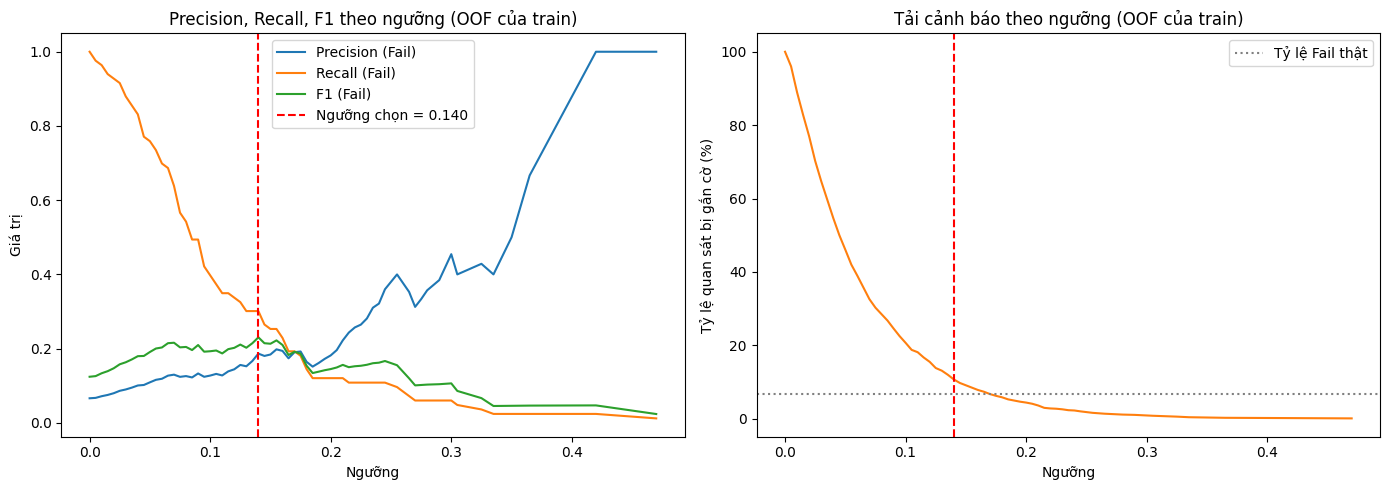

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(scan_table["threshold"], scan_table["precision"], label="Precision (Fail)")
axes[0].plot(scan_table["threshold"], scan_table["recall"], label="Recall (Fail)")
axes[0].plot(scan_table["threshold"], scan_table["f1"], label="F1 (Fail)")
axes[0].axvline(chosen_threshold, color="red", linestyle="--", label=f"Ngưỡng chọn = {chosen_threshold:.3f}")
axes[0].set_xlabel("Ngưỡng")
axes[0].set_ylabel("Giá trị")
axes[0].set_title("Precision, Recall, F1 theo ngưỡng (OOF của train)")
axes[0].legend()

axes[1].plot(scan_table["threshold"], scan_table["alarm_rate"] * 100, color="tab:orange")
axes[1].axvline(chosen_threshold, color="red", linestyle="--")
axes[1].axhline(y_train.mean() * 100, color="gray", linestyle=":", label="Tỷ lệ Fail thật")
axes[1].set_xlabel("Ngưỡng")
axes[1].set_ylabel("Tỷ lệ quan sát bị gắn cờ (%)")
axes[1].set_title("Tải cảnh báo theo ngưỡng (OOF của train)")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_03_threshold_oof.png", dpi=150)
plt.show()

In [22]:
# Lưu OOF và bảng ngưỡng
oof_table.to_csv(RESULTS_DIR / "oof_predictions.csv", index=False)
threshold_table.to_csv(RESULTS_DIR / "threshold_oof.csv", index=False)
print("Đã lưu: oof_predictions.csv và threshold_oof.csv trong", RESULTS_DIR.name)

Đã lưu: oof_predictions.csv và threshold_oof.csv trong results


### Nhận xét

- **Phát hiện:** ngưỡng có F1 của Fail cao nhất trên OOF là **0,14**: Precision 0,187, Recall 0,301, F1 0,230; trên OOF gắn cờ 134/1.253 quan sát (10,7%), gồm TP = 25, FP = 109, FN = 58. Dòng tham chiếu "báo tất cả" có F1 = 0,124, "luôn Pass" có F1 = 0.
- **Ảnh hưởng:** ở ngưỡng đã chọn mô hình bắt được 25/83 Fail (30,1%) và báo nhầm 109 Pass, F1 cao hơn "báo tất cả" nhưng vẫn thấp. Đánh đổi rõ: ví dụ ngưỡng 0,07 đưa Recall lên 0,64 nhưng phải gắn cờ khoảng 32,6% quan sát (F1 = 0,216); điểm OOF của Random Forest chỉ có 64 giá trị phân biệt và lớn nhất 0,47, nên không có ngưỡng nào ≥ 0,5 gắn cờ được quan sát nào.
- **Kết luận:** dùng ngưỡng 0,14 cho mô hình cuối, cố định từ đây. Đây là bảng phát triển mô hình trên 83 Fail nên ngưỡng có thể lạc quan và dao động; notebook 04 sẽ áp đúng ngưỡng này lên test một lần, không chỉnh lại.

### 8.1. Ngưỡng cho Logistic Regression (thêm sau lần xem test đầu tiên)

*Nhãn: Nhóm bổ sung. Dùng đúng quy tắc của mục 8 cho Random Forest, không đổi quy tắc.*

- **Vì sao thêm:** mục 8 chỉ chốt ngưỡng cho Random Forest (mô hình cuối). Ở notebook 04, Logistic Regression mới chỉ có ngưỡng 0,5 nên so sánh với Random Forest chưa cùng điều kiện. Ngưỡng này được **thêm sau lần xem test đầu tiên**, chỉ để so sánh cùng điều kiện.
- **Không dùng test:** ngưỡng được chọn **chỉ từ OOF của train** (`cross_val_predict`, cùng bộ fold `cv` như Random Forest). Notebook này vẫn không dự đoán hay tính chỉ số trên test.
- **Quy tắc (giữ nguyên):** quét ngưỡng bằng vòng `for` trên các điểm số phân biệt; chọn F1 của Fail cao nhất, F1 bằng nhau thì chọn ngưỡng cao hơn; hai dòng tham chiếu "báo tất cả" và "luôn Pass" không tham gia việc chọn. Nếu chính sách của Logistic Regression không có F1 cao hơn cả hai mốc này thì dừng và báo lại, không đổi quy tắc.
- **Không đổi gì khác:** `model_final` vẫn là Random Forest, ngưỡng Random Forest vẫn là ngưỡng đã chọn ở mục 8, cấu hình Logistic Regression (`class_weight="balanced"`, k = 40, C = 1,0) không đổi.

In [23]:
# OOF của Logistic Regression: cùng bộ fold cv, cùng cấu hình như mục 4/6 (balanced, k = 40, C = 1.0)
assert chosen_class_weight == "balanced", "Cấu hình LR đã đổi so với balanced"
lr_oof_pipeline = make_full_pipeline(
    LogisticRegression(max_iter=2000, C=1.0, class_weight="balanced", random_state=SEED)
)

# Lấy cột lớp Fail theo vị trí của nhãn 1 trong classes_ (không giả định cột 1)
lr_classes = list(np.sort(y_train.unique()))
lr_fail_column = lr_classes.index(1)
oof_proba_lr = cross_val_predict(lr_oof_pipeline, X_train_raw, y_train, cv=cv, method="predict_proba")
oof_score_lr = oof_proba_lr[:, lr_fail_column]

assert len(oof_score_lr) == len(y_train) == len(oof_table), "Mỗi mẫu train phải có đúng một điểm OOF"
assert np.array_equal(y_train.to_numpy(), oof_table["y_true"].to_numpy()), "Thứ tự mẫu OOF của LR phải trùng RF"
print("Số điểm OOF của LR:", len(oof_score_lr), "| số điểm số phân biệt:", len(np.unique(oof_score_lr)))
display(pd.Series(oof_score_lr).describe().to_frame("score_fail_lr").T.round(4))

Số điểm OOF của LR: 1253 | số điểm số phân biệt: 1253


,count,mean,std,min,25%,50%,75%,max
score_fail_lr,1253.0,0.33,0.2669,0.0029,0.1099,0.2459,0.4929,1.0


In [24]:
# Quét ngưỡng bằng vòng for, y hệt mục 8 (trên các điểm số phân biệt của OOF)
threshold_rows_lr = []
for threshold_lr_value in np.unique(oof_score_lr):
    row = evaluate_classifier(y_oof, oof_score_lr, threshold_lr_value)
    row["loai"] = "Quét"
    threshold_rows_lr.append(row)

# Hai dòng tham chiếu, cùng cách tính như mục 8
row_all_lr = evaluate_classifier(y_oof, oof_score_lr, 0.0)
row_all_lr["loai"] = "Tham chiếu: báo tất cả"
row_none_lr = evaluate_classifier(y_oof, oof_score_lr, float(np.nextafter(oof_score_lr.max(), np.inf)))
row_none_lr["loai"] = "Tham chiếu: luôn Pass"
threshold_rows_lr.append(row_all_lr)
threshold_rows_lr.append(row_none_lr)

threshold_table_lr = pd.DataFrame(threshold_rows_lr)
scan_table_lr = threshold_table_lr[threshold_table_lr["loai"] == "Quét"]
print("Số ngưỡng đã quét (LR):", len(scan_table_lr))

# Chọn: F1 cao nhất; F1 bằng nhau thì ngưỡng cao hơn
best_f1_lr = scan_table_lr["f1"].max()
tied_lr = scan_table_lr[scan_table_lr["f1"] == best_f1_lr]
threshold_lr = float(tied_lr["threshold"].max())

# Hàm dùng chung trong secom_utils phải cho cùng kết quả
assert threshold_lr == choose_threshold(y_oof, oof_score_lr, strategy="f1"), "choose_threshold lệch với bảng ngưỡng của LR"

threshold_table_lr["duoc_chon"] = threshold_table_lr["threshold"].eq(threshold_lr) & threshold_table_lr["loai"].eq("Quét")
chosen_row_lr = threshold_table_lr[threshold_table_lr["duoc_chon"]].iloc[0]

# Điều kiện dừng đã đặt trước: F1 của chính sách LR phải cao hơn cả hai mốc tham chiếu
beats_all = chosen_row_lr["f1"] > row_all_lr["f1"]
beats_none = chosen_row_lr["f1"] > row_none_lr["f1"]
print("Ngưỡng LR được chọn:", round(threshold_lr, 4), "| số ngưỡng có cùng F1 cao nhất:", len(tied_lr))
print(f"F1 của LR = {chosen_row_lr['f1']:.4f} | 'báo tất cả' = {row_all_lr['f1']:.4f} | 'luôn Pass' = {row_none_lr['f1']:.4f}")
assert beats_all and beats_none, "DỪNG: chính sách LR không có F1 cao hơn cả hai mốc tham chiếu; báo lại, không đổi quy tắc"

display(threshold_table_lr[threshold_table_lr["duoc_chon"]][show_columns].round(4))
display(threshold_table_lr[threshold_table_lr["loai"] != "Quét"][show_columns].round(4))

Số ngưỡng đã quét (LR): 1253
Ngưỡng LR được chọn: 0.8361 | số ngưỡng có cùng F1 cao nhất: 1
F1 của LR = 0.2353 | 'báo tất cả' = 0.1243 | 'luôn Pass' = 0.0000


,loai,threshold,precision,recall,f1,balanced_accuracy,ber,tp,fp,fn,tn,fpr,alarm_rate
1166,Quét,0.8361,0.2299,0.241,0.2353,0.5918,0.4082,20,67,63,1103,0.0573,0.0694


,loai,threshold,precision,recall,f1,balanced_accuracy,ber,tp,fp,fn,tn,fpr,alarm_rate
1253,Tham chiếu: báo tất cả,0.0,0.0662,1.0,0.1243,0.5,0.5,83,1170,0,0,1.0,1.0
1254,Tham chiếu: luôn Pass,1.0,0.0000,0.0,0.0000,0.5,0.5,0,0,83,1170,0.0,0.0


In [25]:
# 10 ngưỡng có F1 cao nhất của LR (độ phẳng của đỉnh F1)
display(scan_table_lr.sort_values(["f1", "threshold"], ascending=[False, False]).head(10)[show_columns[1:]].round(4))

# Bảng đặt cạnh nhau hai chính sách trên OOF-train: LR (ngưỡng mới) và RF (ngưỡng đã chọn ở mục 8)
rf_oof_row = evaluate_classifier(y_oof, oof_score, chosen_threshold)
assert chosen_threshold == 0.14, "Ngưỡng RF đã đổi so với 0,14"

def policy_row(name, metrics):
    return {
        "Chính sách (OOF-train)": name,
        "Ngưỡng": metrics["threshold"],
        "Precision": metrics["precision"], "Recall": metrics["recall"], "F1": metrics["f1"],
        "Tỷ lệ cảnh báo": metrics["alarm_rate"],
        "TP": int(metrics["tp"]), "FP": int(metrics["fp"]), "FN": int(metrics["fn"]), "TN": int(metrics["tn"]),
    }

oof_policy_table = pd.DataFrame([
    policy_row("Logistic Regression @ ngưỡng OOF", chosen_row_lr),
    policy_row("Random Forest @ ngưỡng đã chọn", rf_oof_row),
])
display(oof_policy_table.round(4))
print("Các số trên là OOF của train (phát triển mô hình), không phải kết quả test.")

# Số cũ của RF phải giữ nguyên
assert (round(rf_oof_row["precision"], 3), round(rf_oof_row["recall"], 3), round(rf_oof_row["f1"], 3)) == (0.187, 0.301, 0.230), "OOF của RF @ 0,14 đã đổi"

threshold_table_lr.to_csv(RESULTS_DIR / "threshold_oof_lr.csv", index=False)
print("Đã lưu: threshold_oof_lr.csv trong", RESULTS_DIR.name)

,threshold,precision,recall,f1,balanced_accuracy,ber,tp,fp,fn,tn,fpr,alarm_rate
1166,0.8361,0.2299,0.2410,0.2353,0.5918,0.4082,20,67,63,1103,0.0573,0.0694
1165,0.8348,0.2273,0.2410,0.2339,0.5914,0.4086,20,68,63,1102,0.0581,0.0702
1173,0.8418,0.2375,0.2289,0.2331,0.5884,0.4116,19,61,64,1109,0.0521,0.0638
1147,0.8043,0.2075,0.2651,0.2328,0.5966,0.4034,22,84,61,1086,0.0718,0.0846
1164,0.8337,0.2247,0.2410,0.2326,0.5910,0.4090,20,69,63,1101,0.0590,0.0710
1078,0.6905,0.1714,0.3614,0.2326,0.6188,0.3812,30,145,53,1025,0.1239,0.1397
1172,0.8416,0.2346,0.2289,0.2317,0.5880,0.4120,19,62,64,1108,0.0530,0.0646
1077,0.6897,0.1705,0.3614,0.2317,0.6183,0.3817,30,146,53,1024,0.1248,0.1405
1146,0.7961,0.2056,0.2651,0.2316,0.5962,0.4038,22,85,61,1085,0.0726,0.0854
1163,0.8309,0.2222,0.2410,0.2312,0.5906,0.4094,20,70,63,1100,0.0598,0.0718


,Chính sách (OOF-train),Ngưỡng,Precision,Recall,F1,Tỷ lệ cảnh báo,TP,FP,FN,TN
0,Logistic Regression @ ngưỡng OOF,0.8361,0.2299,0.2410,0.2353,0.0694,20,67,63,1103
1,Random Forest @ ngưỡng đã chọn,0.1400,0.1866,0.3012,0.2304,0.1069,25,109,58,1061


Các số trên là OOF của train (phát triển mô hình), không phải kết quả test.
Đã lưu: threshold_oof_lr.csv trong results


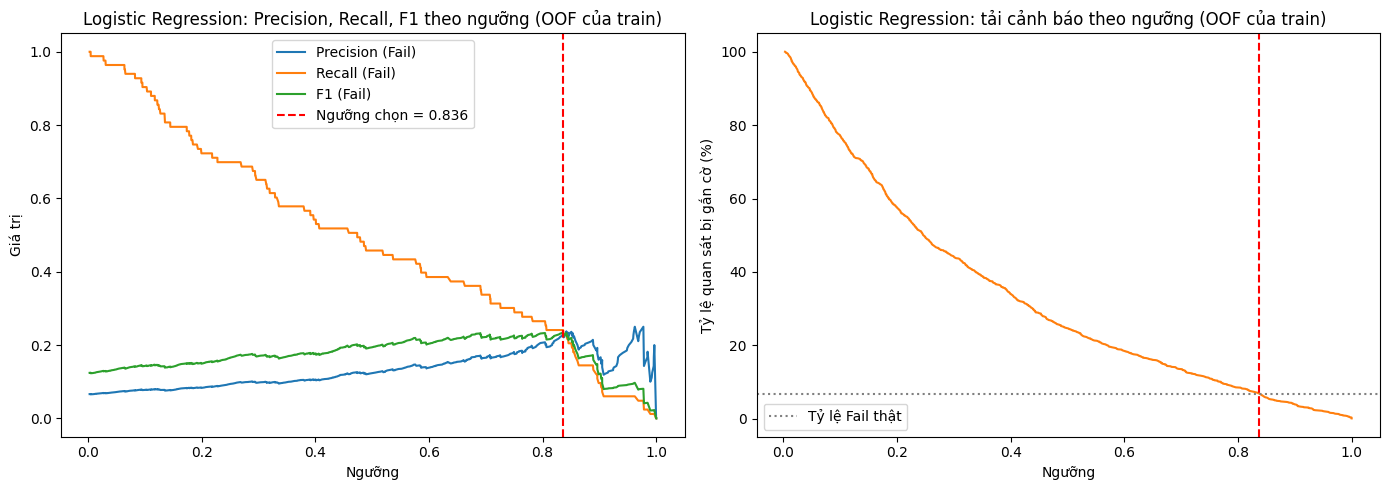

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(scan_table_lr["threshold"], scan_table_lr["precision"], label="Precision (Fail)")
axes[0].plot(scan_table_lr["threshold"], scan_table_lr["recall"], label="Recall (Fail)")
axes[0].plot(scan_table_lr["threshold"], scan_table_lr["f1"], label="F1 (Fail)")
axes[0].axvline(threshold_lr, color="red", linestyle="--", label=f"Ngưỡng chọn = {threshold_lr:.3f}")
axes[0].set_xlabel("Ngưỡng")
axes[0].set_ylabel("Giá trị")
axes[0].set_title("Logistic Regression: Precision, Recall, F1 theo ngưỡng (OOF của train)")
axes[0].legend()

axes[1].plot(scan_table_lr["threshold"], scan_table_lr["alarm_rate"] * 100, color="tab:orange")
axes[1].axvline(threshold_lr, color="red", linestyle="--")
axes[1].axhline(y_train.mean() * 100, color="gray", linestyle=":", label="Tỷ lệ Fail thật")
axes[1].set_xlabel("Ngưỡng")
axes[1].set_ylabel("Tỷ lệ quan sát bị gắn cờ (%)")
axes[1].set_title("Logistic Regression: tải cảnh báo theo ngưỡng (OOF của train)")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_03_threshold_oof_lr.png", dpi=150)
plt.show()

### Nhận xét

- **Phát hiện:** ngưỡng có F1 của Fail cao nhất trên OOF của Logistic Regression là **0,836**: Precision 0,230, Recall 0,241, F1 0,235; gắn cờ 87/1.253 quan sát (6,9%), gồm TP = 20, FP = 67, FN = 63. Hai mốc tham chiếu: "báo tất cả" F1 = 0,124, "luôn Pass" F1 = 0, nên chính sách này cao hơn cả hai và không phải dừng. Cạnh Random Forest ở ngưỡng 0,14 (Precision 0,187, Recall 0,301, F1 0,230; gắn cờ 134 quan sát, 10,7%; TP = 25, FP = 109), hai chính sách ở hai điểm vận hành khác nhau: Logistic Regression gắn cờ ít hơn, Precision cao hơn, Recall thấp hơn.
- **Ảnh hưởng:** chênh F1 giữa hai chính sách chỉ 0,005 (0,235 so với 0,230), tức vài ca trên 83 Fail, nên chưa đủ để nói chính sách nào hơn. Đỉnh F1 của Logistic Regression khá phẳng: 10 ngưỡng đứng đầu có F1 từ 0,231 đến 0,235 và nằm trong khoảng 0,69–0,84; ví dụ ngưỡng 0,69 có Recall 0,361 nhưng gắn cờ khoảng 14,0% quan sát. Ngưỡng cao (0,836) là do `class_weight="balanced"` đẩy điểm số lên cao (trung vị điểm OOF 0,246, phân vị 75% là 0,493), nên điểm này là risk score chứ không phải xác suất đã hiệu chỉnh.
- **Kết luận:** ngưỡng Logistic Regression = 0,836, lưu vào `decision_config.json` (khoá `threshold_lr`, `threshold_rule`). Ngưỡng này được **thêm sau lần xem test đầu tiên** chỉ để so sánh Logistic Regression và Random Forest cùng điều kiện; nó được chọn **chỉ từ OOF của train**, không dùng test, và không thay đổi mô hình cuối (vẫn là Random Forest, ngưỡng 0,14). Giới hạn: OOF chỉ có 83 Fail và ngưỡng được chọn trên chính OOF này nên các con số có thể lạc quan và dao động.

## 9. Bảng so sánh các mô hình

*Nhãn: Điều chỉnh từ lab (Lab 03, cell 37: bảng so sánh), nhưng số liệu là CV/OOF trên train, không phải test.*

Ba bảng: (1) CV của LR và RF ở ngưỡng 0,5; (2) class weight; (3) mô hình cuối với ngưỡng đã chọn trên OOF. **Không trộn với kết quả test.**

In [27]:
cv_model_comparison = pd.DataFrame([lr_row, rf_row])
display(cv_model_comparison.round(4))

cv_model_comparison.to_csv(RESULTS_DIR / "cv_model_comparison.csv", index=False)
class_weight_table.to_csv(RESULTS_DIR / "cv_class_weight.csv", index=False)
print("Đã lưu: cv_model_comparison.csv và cv_class_weight.csv")

,Mô hình,AP_mean,AP_std,Recall_Fail_mean,Recall_Fail_std,Precision_Fail_mean,Precision_Fail_std,F1_Fail_mean,F1_Fail_std,Balanced_Accuracy_mean,Balanced_Accuracy_std,BER_mean,BER_std
0,Logistic Regression (balanced),0.1631,0.0290,0.4581,0.0608,0.1246,0.0213,0.1956,0.0311,0.6137,0.0359,0.3863,0.0359
1,Random Forest (balanced),0.2038,0.0701,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.5000,0.0000


Đã lưu: cv_model_comparison.csv và cv_class_weight.csv


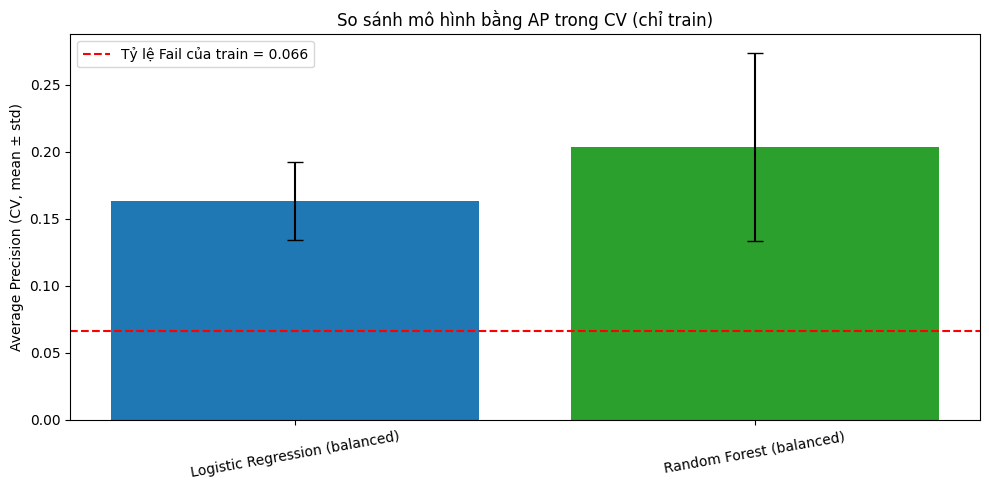

In [28]:
plt.figure(figsize=(10, 5))
plt.bar(cv_model_comparison["Mô hình"], cv_model_comparison["AP_mean"],
        yerr=cv_model_comparison["AP_std"], capsize=6, color=["tab:blue", "tab:green"])
plt.axhline(y_train.mean(), color="red", linestyle="--", label=f"Tỷ lệ Fail của train = {y_train.mean():.3f}")
plt.ylabel("Average Precision (CV, mean ± std)")
plt.title("So sánh mô hình bằng AP trong CV (chỉ train)")
plt.xticks(rotation=10)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_03_cv_model_ap.png", dpi=150)
plt.show()

In [29]:
# Mô hình cuối với ngưỡng đã chọn, tính trên OOF của train
final_summary = pd.DataFrame([
    {
        "Chính sách": "Mô hình cuối + ngưỡng đã chọn (" + final_model_name + ")",
        "Ngưỡng": chosen_threshold,
        "Số cảnh báo": int(chosen_row["tp"] + chosen_row["fp"]),
        "TP": int(chosen_row["tp"]), "FP": int(chosen_row["fp"]), "FN": int(chosen_row["fn"]),
        "Precision": chosen_row["precision"], "Recall": chosen_row["recall"], "F1": chosen_row["f1"],
    },
    {
        "Chính sách": "Tham chiếu: báo tất cả",
        "Ngưỡng": 0.0,
        "Số cảnh báo": int(row_all["tp"] + row_all["fp"]),
        "TP": row_all["tp"], "FP": row_all["fp"], "FN": row_all["fn"],
        "Precision": row_all["precision"], "Recall": row_all["recall"], "F1": row_all["f1"],
    },
    {
        "Chính sách": "Tham chiếu: luôn Pass",
        "Ngưỡng": row_none["threshold"],
        "Số cảnh báo": int(row_none["tp"] + row_none["fp"]),
        "TP": row_none["tp"], "FP": row_none["fp"], "FN": row_none["fn"],
        "Precision": row_none["precision"], "Recall": row_none["recall"], "F1": row_none["f1"],
    },
])
display(final_summary.round(4))
print("Các số trên là OOF của train (phát triển mô hình), không phải kết quả test.")

,Chính sách,Ngưỡng,Số cảnh báo,TP,FP,FN,Precision,Recall,F1
0,Mô hình cuối + ngưỡng đã chọn (random_forest),0.14,134,25,109,58,0.1866,0.3012,0.2304
1,Tham chiếu: báo tất cả,0.00,1253,83,1170,0,0.0662,1.0000,0.1243
2,Tham chiếu: luôn Pass,0.47,0,0,0,83,0.0000,0.0000,0.0000


Các số trên là OOF của train (phát triển mô hình), không phải kết quả test.


### Nhận xét

- **Phát hiện:** theo CV ở ngưỡng 0,5, AP của LR / RF lần lượt là 0,163 / 0,204; mốc tỷ lệ Fail của train là 0,066. Mô hình cuối (Random Forest) với ngưỡng 0,14 cho F1 OOF = 0,230, so với 0,124 của "báo tất cả".
- **Ảnh hưởng:** Random Forest có AP cao nhất nhưng ở ngưỡng 0,5 không gắn cờ quan sát nào, nên bảng ở ngưỡng 0,5 chỉ cho thấy khả năng xếp hạng. Sau khi chọn ngưỡng 0,14 trên OOF, mô hình gắn cờ 134 quan sát (10,7%), bắt 25/83 Fail, F1 = 0,230 so với 0,124 của "báo tất cả".
- **Kết luận:** các con số này chỉ dùng để phát triển mô hình. Chúng chưa phải kết quả đánh giá độc lập; đánh giá chính thức nằm ở notebook 04 trên test.

## 10. Refit, lưu model và cấu hình quyết định

*Nhãn: Điều chỉnh từ lab (Lab 02, cell 48, 50: lưu và nạp lại joblib); nhóm bổ sung: đo thời gian train, kiểm tra model nhận thẳng 590 cột thô.*

- Fit lại cả hai mô hình (Logistic Regression với class weight đã chọn, Random Forest) trên **toàn bộ train**; đo thời gian refit từng mô hình (đây là thời gian một lần fit trên train, không phải thời gian CV).
- Lưu `model_lr.joblib`, `model_rf.joblib`, `model_final.joblib` (pipeline đầy đủ, nhận **590 cột thô**; khi dùng không transform bằng pipeline 02 nữa).
- Lưu `decision_config.json`: model cuối, ngưỡng, class weight, k, thời gian train và danh sách cột gốc đã chọn. Ánh xạ cột gốc làm một lần ở mục 3; notebook 04 đọc lại từ file này.
- Điểm số Fail có thể chưa phải xác suất đã hiệu chỉnh (do class weight); không calibrate sau khi thấy test, nên dashboard sau này gọi đây là risk score.

In [30]:
lr_class_weight = chosen_class_weight
lr_model = make_full_pipeline(LogisticRegression(max_iter=2000, C=1.0, class_weight=lr_class_weight, random_state=SEED))
rf_model = make_full_pipeline(RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED, n_jobs=-1))

# Đo thời gian fit lại trên toàn bộ train (một lần)
start_time = time.perf_counter()
lr_model.fit(X_train_raw, y_train)
lr_train_seconds = time.perf_counter() - start_time

start_time = time.perf_counter()
rf_model.fit(X_train_raw, y_train)
rf_train_seconds = time.perf_counter() - start_time

print(f"Thời gian refit trên train: Logistic Regression {lr_train_seconds:.2f} s | Random Forest {rf_train_seconds:.2f} s")

model_final = lr_model if final_model_name == "logistic_regression" else rf_model
print("Model cuối:", final_model_name)

Thời gian refit trên train: Logistic Regression 0.04 s | Random Forest 0.21 s
Model cuối: random_forest


In [31]:
# Kiểm tra model cuối chọn đúng 40 cột gốc đã ánh xạ ở mục 3 (ánh xạ chỉ làm một lần)
final_preprocess = model_final.named_steps["preprocess"]
final_selector = model_final.named_steps["select"]
final_after_missing = final_preprocess.named_steps["missing_rate"].get_support(indices=True)
final_after_constant = final_after_missing[final_preprocess.named_steps["constant"].get_support(indices=True)]
final_selected_columns = final_after_constant[final_selector.get_support(indices=True)]

assert np.array_equal(final_selected_columns, selected_original_columns), "Model cuối chọn khác cột so với mục 3"
print("Model cuối chọn đúng", len(final_selected_columns), "cột gốc như mục 3.")
print("Số cột thô mà model nhận:", final_preprocess.named_steps["missing_rate"].n_features_in_)

Model cuối chọn đúng 40 cột gốc như mục 3.
Số cột thô mà model nhận: 590


In [32]:
# Lưu ba model
save_artifact(lr_model, "model_lr.joblib")
save_artifact(rf_model, "model_rf.joblib")
saved_final = save_artifact(model_final, "model_final.joblib")

# Lưu decision_config.json (giá trị đổi sang kiểu Python thường)
if isinstance(final_class_weight, dict):
    class_weight_for_json = {str(label): weight for label, weight in final_class_weight.items()}
else:
    class_weight_for_json = final_class_weight   # "balanced" hoặc None

decision_config = {
    "model": final_model_name,
    "threshold": float(chosen_threshold),
    "class_weight": class_weight_for_json,
    "k": int(K_FEATURES),
    "train_time_seconds": {
        "logistic_regression": float(lr_train_seconds),
        "random_forest": float(rf_train_seconds),
    },
    "selected_original_columns": [int(column) for column in selected_original_columns],
}
config_path = ARTIFACT_DIR / "decision_config.json"
with open(config_path, "w", encoding="utf-8") as config_file:
    json.dump(decision_config, config_file, ensure_ascii=False, indent=2)

print("Đã lưu: model_lr.joblib, model_rf.joblib, model_final.joblib, decision_config.json")

Đã lưu: model_lr.joblib, model_rf.joblib, model_final.joblib, decision_config.json


Lưu ngưỡng Logistic Regression (mục 8.1) vào `decision_config.json`: chỉ thêm 2 khoá mới `threshold_lr` và `threshold_rule`, không đổi khoá cũ.

In [33]:
# Thêm đúng 2 khoá mới vào decision_config.json; giữ nguyên mọi khoá cũ (model, threshold của RF, ...)
THRESHOLD_RULE_TEXT = "F1 Fail cao nhất trên OOF-train; bằng F1 thì chọn ngưỡng cao hơn"
with open(config_path, encoding="utf-8") as config_file:
    config_before = json.load(config_file)
assert "threshold_lr" not in config_before and "threshold_rule" not in config_before, "Hai khoá mới đã tồn tại"

config_after = dict(config_before)
config_after["threshold_lr"] = float(threshold_lr)
config_after["threshold_rule"] = THRESHOLD_RULE_TEXT
with open(config_path, "w", encoding="utf-8") as config_file:
    json.dump(config_after, config_file, ensure_ascii=False, indent=2)

# Kiểm tra: khoá cũ không đổi, chỉ thêm 2 khoá, model cuối vẫn là RF với ngưỡng 0,14
with open(config_path, encoding="utf-8") as config_file:
    config_check = json.load(config_file)
assert all(config_check[key] == config_before[key] for key in config_before), "Khoá cũ trong decision_config.json bị đổi"
assert set(config_check) - set(config_before) == {"threshold_lr", "threshold_rule"}
assert config_check["model"] == "random_forest" and config_check["threshold"] == 0.14, "Mô hình cuối hoặc ngưỡng RF đã đổi"
print("Khoá trong decision_config.json:", list(config_check.keys()))
print("threshold_lr =", round(config_check["threshold_lr"], 4), "| threshold_rule =", config_check["threshold_rule"])

Khoá trong decision_config.json: ['model', 'threshold', 'class_weight', 'k', 'train_time_seconds', 'selected_original_columns', 'threshold_lr', 'threshold_rule']
threshold_lr = 0.8361 | threshold_rule = F1 Fail cao nhất trên OOF-train; bằng F1 thì chọn ngưỡng cao hơn


In [34]:
# Nạp lại và kiểm tra: cùng điểm số, model nhận 590 cột thô
reloaded_final = load_artifact("model_final.joblib")
sample_rows = X_train_raw.iloc[:20]

score_before = model_final.predict_proba(sample_rows)[:, fail_column]
score_after = reloaded_final.predict_proba(sample_rows)[:, fail_column]
print("Sai khác lớn nhất giữa điểm trước và sau khi nạp lại (20 mẫu train):", np.max(np.abs(score_before - score_after)))
assert np.allclose(score_before, score_after)

with open(config_path, encoding="utf-8") as config_file:
    loaded_config = json.load(config_file)
print("Khoá trong decision_config.json:", list(loaded_config.keys()))
print("Model:", loaded_config["model"], "| ngưỡng:", round(loaded_config["threshold"], 4),
      "| class_weight:", loaded_config["class_weight"], "| k:", loaded_config["k"])
print("Số cột gốc đã chọn:", len(loaded_config["selected_original_columns"]))
print("Kích thước model_final:", round(saved_final.stat().st_size / 1024, 1), "KB")

Sai khác lớn nhất giữa điểm trước và sau khi nạp lại (20 mẫu train): 0.0
Khoá trong decision_config.json: ['model', 'threshold', 'class_weight', 'k', 'train_time_seconds', 'selected_original_columns', 'threshold_lr', 'threshold_rule']
Model: random_forest | ngưỡng: 0.14 | class_weight: balanced | k: 40
Số cột gốc đã chọn: 40
Kích thước model_final: 2604.7 KB


### Nhận xét

- **Phát hiện:** refit trên toàn bộ train mất dưới 1 giây với mỗi mô hình (giá trị chính xác ở output trên và trong `decision_config.json`). Model cuối nạp lại cho điểm số giống hệt (sai khác 0) và chọn đúng 40 cột gốc như mục 3.
- **Ảnh hưởng:** model nhận thẳng 590 cột thô nên notebook 04 và dashboard không cần transform thêm; thời gian train đo trên một máy, một lần fit, chỉ để tham khảo chi phí tính toán.
- **Kết luận:** artifact đã đủ cho notebook 04: ba model, `decision_config.json` (model, ngưỡng, class weight, k, thời gian train, cột gốc). Tiêu chí chấp nhận được viết ở đầu notebook 04, không lưu thành file.

## Kết luận

Notebook này so sánh Logistic Regression (LR) và Random Forest (RF) bằng CV 5-fold trên train (1.253 mẫu, 83 Fail); mỗi fold fit lại cả pipeline từ dữ liệu thô nên không rò rỉ, và không dùng test. Cả hai vượt mốc tỷ lệ Fail của train (AP 0,066): LR đạt AP 0,163 ± 0,029, RF đạt 0,204 ± 0,070; RF được chọn theo quy tắc AP, nhưng chênh lệch 0,041 nhỏ hơn độ lệch chuẩn giữa các fold nên không khẳng định RF hơn chắc chắn. Ba mức class weight cho AP gần nhau (0,152–0,165), nên giữ `balanced`. Ở ngưỡng 0,5 RF không gắn cờ quan sát nào; ngưỡng chọn bằng F1 trên OOF là 0,14, gắn cờ 134/1.253 quan sát, bắt 25/83 Fail với 109 báo nhầm, F1 = 0,230 so với 0,124 của "báo tất cả". Hạn chế: kết quả khiêm tốn, ngưỡng chọn trên chính OOF có thể lạc quan, điểm số chưa hiệu chỉnh. Notebook 04 sẽ nạp `model_final.joblib` và `decision_config.json` để đánh giá một lần trên test.

## Điểm cần ghi nhớ

- CV chỉ chạy trên `X_train_raw`; mỗi fold fit lại cả chuỗi `MissingRateSelector → median imputer → VarianceThreshold → Scaler → SelectKBest → Classifier`, nên không rò rỉ từ fold validation.
- Notebook này không dự đoán hay tính chỉ số trên test; model, class weight và ngưỡng đều chốt bằng CV/OOF của train.
- Chọn mô hình theo AP trung bình CV; chênh lệch nhỏ hơn độ lệch chuẩn giữa các fold thì không khẳng định chắc chắn.
- Ngưỡng chọn theo F1 trên OOF; hai dòng tham chiếu "báo tất cả" và "luôn Pass" cho biết mốc cần vượt.
- Cột gốc đã chọn được ánh xạ một lần ở mục 3 và lưu trong `decision_config.json`.
- Điểm số Fail có thể chưa hiệu chỉnh: gọi là risk score, không gọi là xác suất.